# Monte Carlo Portfolio Simulation (corrected version)

## Project objective

This project uses Monte Carlo simulation to estimate possible future portfolio outcomes.

The project will:

1. Download historical asset prices.
2. Calculate historical returns and risk.
3. Build a diversified portfolio.
4. Simulate 10,000 possible future portfolio paths with three different models.
5. Estimate possible final portfolio values.
6. Calculate the probability of loss.
7. Calculate Value at Risk and Expected Shortfall at meaningful horizons (1 day, 10 days, 1 year, 10 years).
8. Test optimistic, base and pessimistic scenarios.
9. Compare three allocations (conservative, balanced, growth).

### What changed compared with the first version

| Issue in the first version | Fix |
|---|---|
| Sample mean treated as the *true* mean, so risk was understated | Each simulated path draws its own mean return (parameter uncertainty) |
| IID Student-t "fat tails" vanished over 2,520 days (central limit theorem) | Replaced by a **block bootstrap** of historical returns, which keeps real crashes and volatility clustering |
| VaR / ES were clipped to $0.00 at the 10-year horizon | Reported **unclipped** at 1-day, 10-day, 1-year and 10-year horizons |
| Drawdown ignored the starting value | Starting value is now the first row of every path |
| Only a "stressed" scenario | Optimistic, base and pessimistic scenarios |
| Allocation comparison used 5,000 simulations vs 10,000 elsewhere | One function, same settings and seed everywhere |
| Correlation limitation did not match the method | Method and limitations now describe the same thing |

## What is Monte Carlo simulation?

Imagine rolling a die once.

You cannot know the exact number before you roll it.

However, if you roll the die 10,000 times, you can understand:

- the most common results;
- the best possible results;
- the worst possible results;
- how often each result happens.

Financial markets are more complicated than dice, but the main idea is similar.

A Monte Carlo simulation creates thousands of possible market paths so that we can study portfolio uncertainty and risk.

In [1]:
!pip install -q yfinance

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.display import Markdown, display

print("All tools are ready.")

All tools are ready.


## Portfolio assets

The portfolio contains four asset classes:

- SPY: large US companies
- QQQ: technology-focused US companies
- BND: US bonds
- GLD: gold

The portfolio is simplified for educational purposes.

**Rebalancing assumption:** the portfolio return is `weights x asset returns` every day, which means the portfolio is
implicitly **rebalanced back to the target weights every day**. Real portfolios drift between rebalancing dates.

In [4]:
tickers = ["SPY", "QQQ", "BND", "GLD"]

asset_names = {
    "SPY": "US Equities",
    "QQQ": "Technology Equities",
    "BND": "US Bonds",
    "GLD": "Gold"
}

weights = np.array([0.40, 0.25, 0.25, 0.10])
assert np.isclose(weights.sum(), 1.0), "Weights must sum to 1"

portfolio_allocation = pd.DataFrame({
    "Ticker": tickers,
    "Asset": [asset_names[t] for t in tickers],
    "Weight (%)": weights * 100
})
portfolio_allocation

,Ticker,Asset,Weight (%)
0,SPY,US Equities,40.0
1,QQQ,Technology Equities,25.0
2,BND,US Bonds,25.0
3,GLD,Gold,10.0


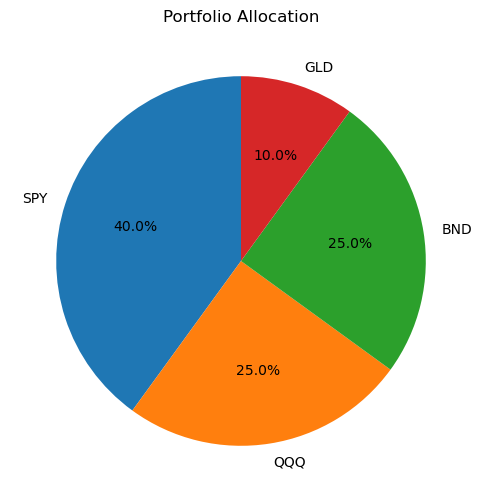

In [5]:
plt.figure(figsize=(8, 6))
plt.pie(
    portfolio_allocation["Weight (%)"],
    labels=portfolio_allocation["Ticker"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Portfolio Allocation")
plt.show()

In [6]:
prices = yf.download(
    tickers=tickers,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"][tickers]

print("Rows:", prices.shape[0], "| Assets:", prices.shape[1])
print("Period:", prices.index[0].date(), "to", prices.index[-1].date())
print("\nMissing values before cleaning:")
print(prices.isna().sum())

prices = prices.ffill().dropna()

print("\nMissing values after cleaning:")
print(prices.isna().sum())
prices.head()

Rows: 2766 | Assets: 4
Period: 2015-01-02 to 2025-12-31

Missing values before cleaning:
Ticker
SPY    0
QQQ    0
BND    0
GLD    0
dtype: int64

Missing values after cleaning:
Ticker
SPY    0
QQQ    0
BND    0
GLD    0
dtype: int64


Ticker,SPY,QQQ,BND,GLD
Date,,,,
2015-01-02,169.267502,94.462708,58.583797,114.080002
2015-01-05,166.210648,93.077065,58.753883,115.800003
2015-01-06,164.645096,91.829063,58.924065,117.120003
2015-01-07,166.696762,93.012848,58.959408,116.430000
2015-01-08,169.654755,94.793076,58.867329,115.940002


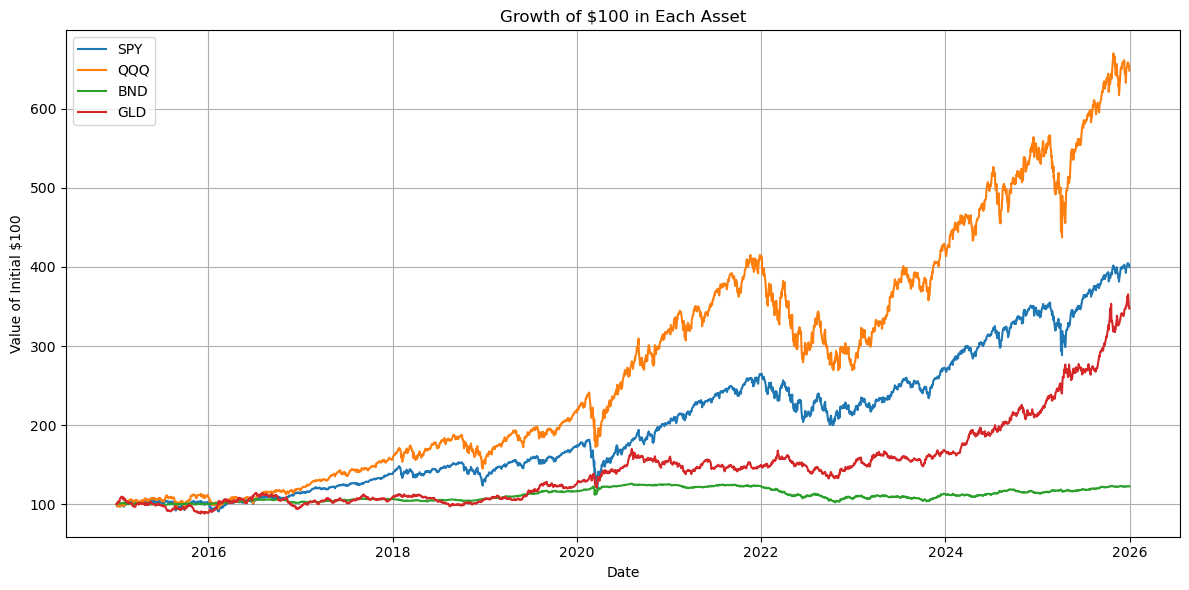

In [7]:
normalized_prices = prices / prices.iloc[0] * 100

plt.figure(figsize=(12, 6))
for ticker in tickers:
    plt.plot(normalized_prices.index, normalized_prices[ticker], label=ticker)

plt.title("Growth of $100 in Each Asset")
plt.xlabel("Date")
plt.ylabel("Value of Initial $100")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
daily_returns = prices.pct_change().dropna()

print(daily_returns.head())
print(daily_returns.shape)

Ticker           SPY       QQQ       BND       GLD
Date                                              
2015-01-05 -0.018059 -0.014669  0.002903  0.015077
2015-01-06 -0.009419 -0.013408  0.002897  0.011399
2015-01-07  0.012461  0.012891  0.000600 -0.005891
2015-01-08  0.017745  0.019140 -0.001562 -0.004209
2015-01-09 -0.008013 -0.006583  0.001686  0.011385
(2765, 4)


## Historical returns and risk

Two kinds of average return are shown:

- **Arithmetic** (mean daily return x 252): what the simulation uses as its starting estimate.
- **CAGR** (geometric): what an investor actually earned per year, compounding included. It is always lower than the arithmetic figure, and the gap grows with volatility.

> **Sample-period warning:** 2015-2025 was an unusually strong period for US equities (especially QQQ) and gold.
> Assuming the same returns for the next ten years is optimistic. Treat the base-case numbers as
> *"what happens if the future looks like this sample"*, not as a forecast.

In [9]:
trading_days = 252

daily_returns = prices.pct_change().dropna()
n_obs = len(daily_returns)
sample_years = n_obs / trading_days

asset_statistics = pd.DataFrame({
    "Arithmetic Return (%)": daily_returns.mean() * trading_days * 100,
    "CAGR (%)": ((prices.iloc[-1] / prices.iloc[0]) ** (1 / sample_years) - 1) * 100,
    "Annual Volatility (%)": daily_returns.std() * np.sqrt(trading_days) * 100,
})

print(f"Observations: {n_obs} trading days ({sample_years:.1f} years)")
asset_statistics.round(2)

Observations: 2765 trading days (11.0 years)


,Arithmetic Return (%),CAGR (%),Annual Volatility (%)
Ticker,,,
SPY,14.22,13.46,17.79
QQQ,19.46,18.57,21.98
BND,2.01,1.88,5.36
GLD,12.44,12.02,14.75


In [10]:
correlation_matrix = daily_returns.corr()
correlation_matrix.round(2)

Ticker,SPY,QQQ,BND,GLD
Ticker,,,,
SPY,1.00,0.93,0.11,0.04
QQQ,0.93,1.00,0.11,0.05
BND,0.11,0.11,1.00,0.33
GLD,0.04,0.05,0.33,1.00


In [11]:
# Portfolio daily returns (daily-rebalanced to fixed weights)
portfolio_daily_returns = daily_returns @ weights
portfolio_daily_returns.name = "Portfolio Return"

expected_annual_return = portfolio_daily_returns.mean() * trading_days
annual_portfolio_volatility = portfolio_daily_returns.std() * np.sqrt(trading_days)
portfolio_cagr = (1 + portfolio_daily_returns).prod() ** (1 / sample_years) - 1

# Standard error of the estimated mean: how uncertain is that mean, given only ~11 years of data?
annual_return_std_error = annual_portfolio_volatility / np.sqrt(sample_years)

print(f"Expected annual return (arithmetic): {expected_annual_return:.2%}")
print(f"Realised CAGR over the sample:       {portfolio_cagr:.2%}")
print(f"Annual volatility:                   {annual_portfolio_volatility:.2%}")
print(f"Std. error of the mean return:       {annual_return_std_error:.2%}  (this is large!)")

Expected annual return (arithmetic): 12.30%
Realised CAGR over the sample:       12.16%
Annual volatility:                   12.83%
Std. error of the mean return:       3.87%  (this is large!)


The standard error above is the key number. With only about 11 years of data, the *true* expected return could easily be
several percentage points above or below the sample estimate. The original version ignored this and treated the sample mean
as exactly right, which made the portfolio look much safer than the data justify.

## Simulation engine

One function runs every model and scenario so that all comparisons use identical settings.

Three models are available:

| Model | Shocks | Mean return |
|---|---|---|
| `normal`, no parameter uncertainty | Normal, IID | Fixed at the sample mean (the first version's approach) |
| `normal`, with parameter uncertainty | Normal, IID | Drawn per path from N(sample mean, standard error) |
| `bootstrap`, with parameter uncertainty | Random **21-day blocks** of historical daily returns (demeaned) | Drawn per path from N(sample mean, standard error) |

The block bootstrap re-uses real historical days in consecutive blocks, so it keeps fat tails, crash periods and
volatility clustering, and it keeps the correlations between assets because the portfolio return already embeds them.

In [12]:
initial_investment = 100_000
target_value = 200_000

years = 10
simulation_days = years * trading_days
number_of_simulations = 10_000
chunk_size = 2_000            # simulate in chunks to keep memory use low
block_length = 21             # about one trading month
random_seed = 42

horizons = {1: "1 day", 10: "10 days", 252: "1 year", simulation_days: "10 years"}

In [13]:
def simulate(
    returns,
    model="bootstrap",              # "normal" or "bootstrap"
    param_uncertainty=True,         # draw a different mean return for every path
    return_shift=0.0,               # annual shift to the mean return (scenario analysis)
    vol_multiplier=1.0,             # scale volatility (scenario analysis)
    n_sims=number_of_simulations,
    n_days=simulation_days,
    initial=initial_investment,
    seed=random_seed,
    keep_paths=100,
):
    rng = np.random.default_rng(seed)

    r = np.asarray(returns, dtype=float)
    n = len(r)
    mu_d = r.mean()
    sd_d = r.std(ddof=1)
    se_d = sd_d / np.sqrt(n)        # standard error of the daily mean
    centered = r - mu_d

    ending, max_dd = [], []
    horizon_returns = {h: [] for h in horizons}
    sample_paths = None

    done = 0
    while done < n_sims:
        m = min(chunk_size, n_sims - done)

        # ---- shocks
        if model == "normal":
            shocks = rng.normal(0.0, sd_d, size=(n_days, m))
        elif model == "bootstrap":
            n_blocks = int(np.ceil(n_days / block_length))
            starts = rng.integers(0, n, size=(n_blocks, 1, m))
            offsets = np.arange(block_length).reshape(1, -1, 1)
            idx = ((starts + offsets) % n).reshape(n_blocks * block_length, m)[:n_days]
            shocks = centered[idx]
        else:
            raise ValueError("model must be 'normal' or 'bootstrap'")
        shocks = shocks * vol_multiplier

        # ---- drift (optionally uncertain)
        drift = mu_d + return_shift / trading_days
        if param_uncertainty:
            drift = rng.normal(drift, se_d * vol_multiplier, size=(1, m))

        daily = drift + shocks

        # ---- paths, with the starting value as row 0
        paths = initial * np.cumprod(1.0 + daily, axis=0)
        paths = np.vstack([np.full((1, m), float(initial)), paths])

        ending.append(paths[-1])
        peaks = np.maximum.accumulate(paths, axis=0)
        max_dd.append((paths / peaks - 1.0).min(axis=0))
        for h in horizons:
            horizon_returns[h].append(paths[h] / initial - 1.0)

        if sample_paths is None:
            sample_paths = paths[:, :keep_paths].copy()

        done += m

    return {
        "ending": np.concatenate(ending),
        "max_dd": np.concatenate(max_dd),
        "horizon_returns": {h: np.concatenate(v) for h, v in horizon_returns.items()},
        "sample_paths": sample_paths,
    }


def summarize(res, initial=initial_investment, target=target_value):
    e = res["ending"]
    return {
        "5th percentile": np.percentile(e, 5),
        "25th percentile": np.percentile(e, 25),
        "Median": np.percentile(e, 50),
        "75th percentile": np.percentile(e, 75),
        "95th percentile": np.percentile(e, 95),
        "P(ending below start)": np.mean(e < initial),
        "P(reaching target)": np.mean(e >= target),
        "Median max drawdown": np.median(res["max_dd"]),
        "5th pct max drawdown": np.percentile(res["max_dd"], 5),
        "P(drawdown >= 20%)": np.mean(res["max_dd"] <= -0.20),
    }


def var_es_table(res, initial=initial_investment, alpha=0.05):
    rows = []
    for h, label in horizons.items():
        ret = res["horizon_returns"][h]
        q = np.percentile(ret, alpha * 100)
        rows.append({
            "Horizon": label,
            "95% VaR ($)": -q * initial,
            "95% VaR (%)": -q,
            "95% ES ($)": -ret[ret <= q].mean() * initial,
            "95% ES (%)": -ret[ret <= q].mean(),
        })
    return pd.DataFrame(rows)


money = lambda v: f"${v:,.0f}"
pct = lambda v: f"{v:.2%}"

## Run the three models

All three use the same number of paths, the same horizon and the same seed.

In [14]:
portfolio_series = portfolio_daily_returns.to_numpy()

results = {
    "Normal, fixed mean (first version)": simulate(portfolio_series, "normal", param_uncertainty=False),
    "Normal + parameter uncertainty":     simulate(portfolio_series, "normal", param_uncertainty=True),
    "Bootstrap + parameter uncertainty":  simulate(portfolio_series, "bootstrap", param_uncertainty=True),
}

BASE = "Bootstrap + parameter uncertainty"
base = results[BASE]

model_rows = {name: summarize(res) for name, res in results.items()}
model_comparison = pd.DataFrame(model_rows)

display_fmt = model_comparison.copy().astype(object)
for metric in display_fmt.index:
    is_pct = metric.startswith("P(") or "drawdown" in metric
    display_fmt.loc[metric] = [pct(v) if is_pct else money(v) for v in model_comparison.loc[metric]]
display_fmt

,"Normal, fixed mean (first version)",Normal + parameter uncertainty,Bootstrap + parameter uncertainty
5th percentile,"$160,464","$125,159","$130,816"
25th percentile,"$239,075","$214,395","$221,894"
Median,"$315,510","$317,888","$317,715"
75th percentile,"$414,454","$461,132","$457,720"
95th percentile,"$624,886","$811,014","$752,106"
P(ending below start),0.15%,2.18%,1.66%
P(reaching target),86.47%,78.80%,80.79%
Median max drawdown,-20.25%,-20.33%,-20.86%
5th pct max drawdown,-32.32%,-35.26%,-35.91%
P(drawdown >= 20%),52.13%,52.03%,55.18%


**How to interpret the results:**

The median portfolio value remains relatively similar across the three models, at approximately \$316,000 –\$318,000 after 10 years. However, the lower-tail outcomes differ noticeably.

When parameter uncertainty is included, the 5th-percentile portfolio value decreases from \$160,464 to \$125,159 under the normal model. The estimated probability of ending below the initial \$100,000 investment also increases from 0.15% to 2.18%.

The bootstrap model produces a 5th-percentile value of \$130,816 and a 1.66% probability of ending below the initial investment. It also produces a higher probability of experiencing a maximum drawdown of at least 20% (55.18%), compared with 52.13% under the fixed-mean model.

These results illustrate that accounting for uncertainty in estimated returns and resampling historical return patterns can materially affect simulated downside risk, even when median outcomes remain similar. These are model-dependent estimates, not guarantees of future performance.

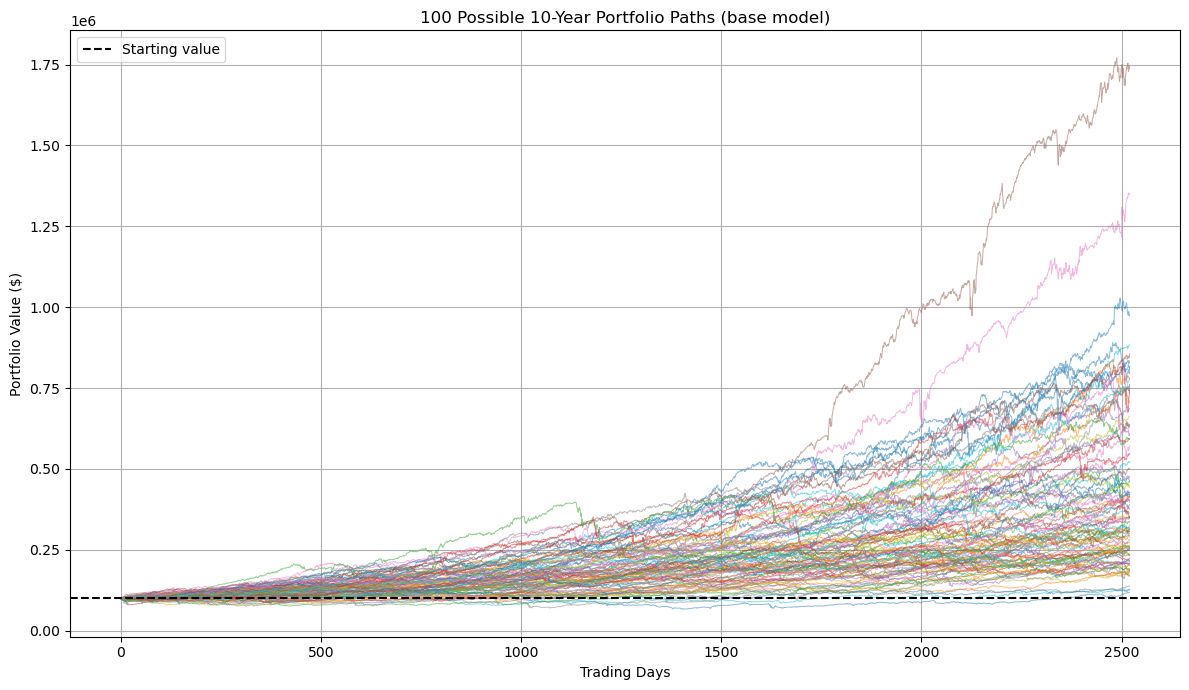

In [15]:
plt.figure(figsize=(12, 7))
plt.plot(base["sample_paths"], linewidth=0.7, alpha=0.5)
plt.axhline(initial_investment, linestyle="--", color="black", label="Starting value")
plt.title("100 Possible 10-Year Portfolio Paths (base model)")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value ($)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

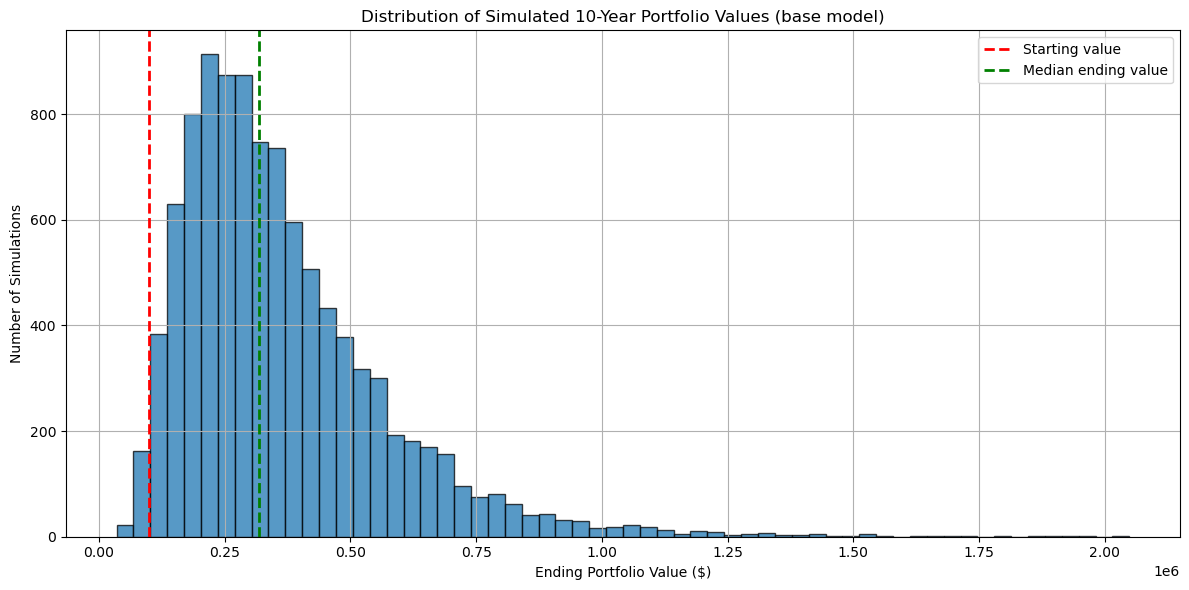

In [16]:
ending_values = base["ending"]
median_ending_value = np.median(ending_values)

plt.figure(figsize=(12, 6))
plt.hist(ending_values, bins=60, edgecolor="black", alpha=0.75)
plt.axvline(initial_investment, linestyle="--", linewidth=2, color="red", label="Starting value")
plt.axvline(median_ending_value, linestyle="--", linewidth=2, color="green", label="Median ending value")
plt.title("Distribution of Simulated 10-Year Portfolio Values (base model)")
plt.xlabel("Ending Portfolio Value ($)")
plt.ylabel("Number of Simulations")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

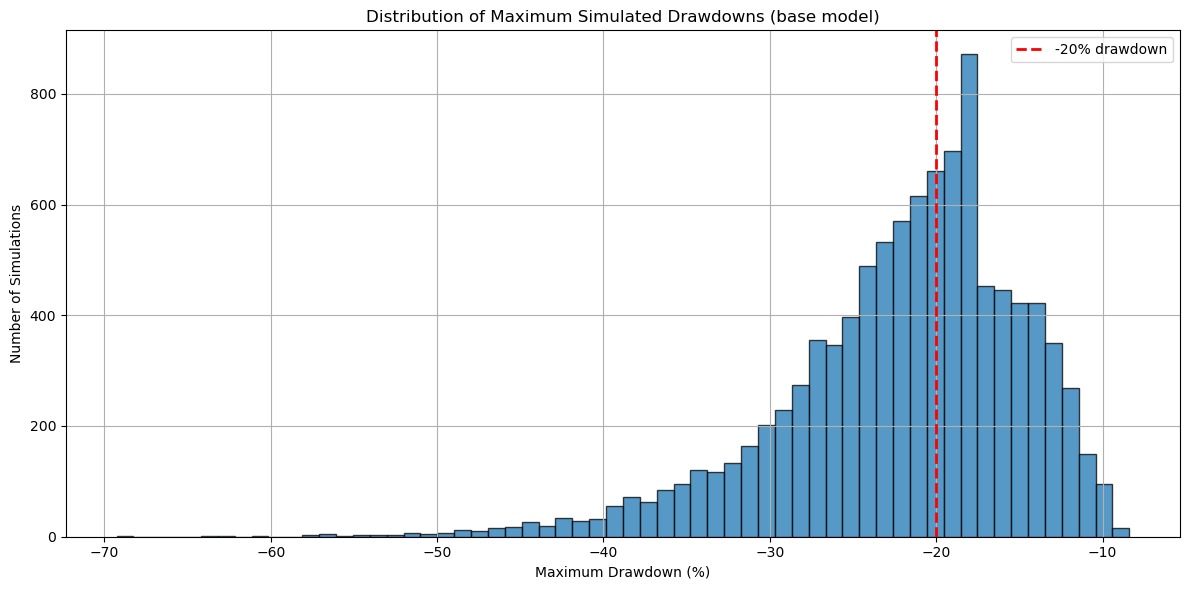

In [17]:
plt.figure(figsize=(12, 6))
plt.hist(base["max_dd"] * 100, bins=60, edgecolor="black", alpha=0.75)
plt.axvline(-20, linestyle="--", linewidth=2, color="red", label="-20% drawdown")
plt.title("Distribution of Maximum Simulated Drawdowns (base model)")
plt.xlabel("Maximum Drawdown (%)")
plt.ylabel("Number of Simulations")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Main Findings from the Monte Carlo Simulation

### 1. 100 Possible 10-Year Portfolio Paths

- All simulated paths begin with an initial investment of $100,000.
- The paths spread out over time as daily returns compound, illustrating uncertainty in long-term investment outcomes.
- Most displayed paths show growth, but the final portfolio values vary considerably.
- A few paths achieve substantially higher values than the majority.

**Main Finding:** The portfolio has the potential to grow over 10 years, but the final outcome varies significantly across simulated investment paths.

### 2. Distribution of Simulated 10-Year Portfolio Values

- The median ending portfolio value is approximately $317,715.
- Approximately 80.79% of simulations reach the target of $200,000.
- Approximately 1.66% of simulations finish below the initial investment of $100,000.
- The distribution shows a wide range of possible ending values, including some unusually high outcomes.

**Main Finding:** The simulation suggests potential for long-term wealth accumulation, but reaching the target is not guaranteed.

### 3. Distribution of Maximum Simulated Drawdowns

- The histogram shows the worst peak-to-trough decline experienced during each simulated investment path.
- Approximately 55.18% of simulations experience a maximum drawdown of at least 20%.
- Some simulated paths experience considerably deeper declines.
- A portfolio can experience a substantial temporary decline and still finish with a positive overall return.

**Main Finding:** Even when long-term growth is possible, investors may need to withstand substantial temporary losses along the way.

### Overall Conclusion

The simulation demonstrates that potential returns, uncertainty in ending wealth, and downside risk should be evaluated together. While the results suggest potential for long-term portfolio growth, they also highlight the possibility of significant temporary losses.

These findings are conditional on the historical data and simulation assumptions. They represent possible scenarios rather than guaranteed predictions of future performance.


## Value at Risk and Expected Shortfall

- **VaR (95%)**: the loss that is exceeded in only 5% of simulations over the given horizon.
- **Expected Shortfall (95%)**: the *average* loss in that worst 5%.

Values are reported **unclipped**: a negative number means that even the worst 5% of paths is still a gain at that horizon.
A 10-year VaR is rarely meaningful for a growth portfolio, so the shorter horizons are the ones to read.

In [18]:
risk_table = var_es_table(base)

risk_display = risk_table.copy().astype(object)
risk_display["95% VaR ($)"] = risk_table["95% VaR ($)"].map(lambda v: f"${v:,.0f}")
risk_display["95% ES ($)"] = risk_table["95% ES ($)"].map(lambda v: f"${v:,.0f}")
risk_display["95% VaR (%)"] = risk_table["95% VaR (%)"].map(pct)
risk_display["95% ES (%)"] = risk_table["95% ES (%)"].map(pct)
risk_display

,Horizon,95% VaR ($),95% VaR (%),95% ES ($),95% ES (%)
0,1 day,"$1,220",1.22%,"$1,934",1.93%
1,10 days,"$3,544",3.54%,"$5,561",5.56%
2,1 year,"$8,297",8.30%,"$14,194",14.19%
3,10 years,"$-30,816",-30.82%,"$-5,274",-5.27%


## Optimistic, base and pessimistic scenarios

Each scenario changes the annual mean return and the volatility, and re-runs the base model.

| Scenario | Change in annual return | Volatility multiplier |
|---|---|---|
| Optimistic | +2 percentage points | x 0.90 |
| Base | none | x 1.00 |
| Pessimistic | -3 percentage points | x 1.25 |

In [19]:
scenarios = {
    "Optimistic":  dict(return_shift=+0.02, vol_multiplier=0.90),
    "Base":        dict(return_shift=0.00,  vol_multiplier=1.00),
    "Pessimistic": dict(return_shift=-0.03, vol_multiplier=1.25),
}

scenario_rows = []
for name, params in scenarios.items():
    res = simulate(portfolio_series, "bootstrap", param_uncertainty=True, **params)
    s = summarize(res)
    scenario_rows.append({
        "Scenario": name,
        "Median Ending Value": money(s["Median"]),
        "5th-Percentile Ending Value": money(s["5th percentile"]),
        "P(ending below start)": pct(s["P(ending below start)"]),
        "P(reaching target)": pct(s["P(reaching target)"]),
        "Median max drawdown": pct(s["Median max drawdown"]),
    })

pd.DataFrame(scenario_rows)

,Scenario,Median Ending Value,5th-Percentile Ending Value,P(ending below start),P(reaching target),Median max drawdown
0,Optimistic,"$393,906","$177,322",0.23%,91.86%,-17.57%
1,Base,"$317,715","$130,816",1.66%,80.79%,-20.86%
2,Pessimistic,"$225,147","$74,026",11.29%,57.13%,-29.55%


## Comparing allocations

All allocations are evaluated using the same bootstrap model, simulation settings, random seed, and 10,000 simulation paths. Using the same seed makes the comparisons reproducible and helps maintain consistency across simulations. The differences in outcomes primarily reflect the different portfolio allocations, although some simulation variability may remain.

In [20]:
portfolio_options = {
    "Conservative": np.array([0.20, 0.10, 0.60, 0.10]),
    "Balanced":     np.array([0.40, 0.25, 0.25, 0.10]),
    "Growth":       np.array([0.50, 0.35, 0.05, 0.10]),
}

allocation_rows = []
for name, w in portfolio_options.items():
    assert np.isclose(w.sum(), 1.0)
    series = (daily_returns @ w).to_numpy()
    res = simulate(series, "bootstrap", param_uncertainty=True)
    s = summarize(res)
    allocation_rows.append({
        "Portfolio": name,
        "Annual Return": pct(series.mean() * trading_days),
        "Annual Volatility": pct(series.std(ddof=1) * np.sqrt(trading_days)),
        "Median Ending Value": money(s["Median"]),
        "5th Percentile": money(s["5th percentile"]),
        "P(ending below start)": pct(s["P(ending below start)"]),
        "Median max drawdown": pct(s["Median max drawdown"]),
    })

allocation_display = pd.DataFrame(allocation_rows)
allocation_display

,Portfolio,Annual Return,Annual Volatility,Median Ending Value,5th Percentile,P(ending below start),Median max drawdown
0,Conservative,7.24%,7.25%,"$201,127","$119,553",1.43%,-12.90%
1,Balanced,12.30%,12.83%,"$317,715","$130,816",1.66%,-20.86%
2,Growth,15.26%,16.49%,"$405,368","$131,408",2.27%,-25.96%


## Summary of the base model

In [21]:
s = summarize(base)
one_year = risk_table.set_index("Horizon").loc["1 year"]

simulation_summary = pd.DataFrame({
    "Metric": [
        "Starting portfolio value",
        "Expected annual return (sample, arithmetic)",
        "Annual volatility (sample)",
        "Median ending value",
        "5th-percentile ending value",
        "95th-percentile ending value",
        "Probability of ending below the start",
        f"Probability of reaching {money(target_value)}",
        "95% 1-year VaR",
        "95% 1-year Expected Shortfall",
        "Median maximum drawdown",
        "Probability of at least a 20% drawdown",
    ],
    "Result": [
        money(initial_investment),
        pct(expected_annual_return),
        pct(annual_portfolio_volatility),
        money(s["Median"]),
        money(s["5th percentile"]),
        money(s["95th percentile"]),
        pct(s["P(ending below start)"]),
        pct(s["P(reaching target)"]),
        f"{money(one_year['95% VaR ($)'])} ({pct(one_year['95% VaR (%)'])})",
        f"{money(one_year['95% ES ($)'])} ({pct(one_year['95% ES (%)'])})",
        pct(s["Median max drawdown"]),
        pct(s["P(drawdown >= 20%)"]),
    ],
})
simulation_summary

,Metric,Result
0,Starting portfolio value,"$100,000"
1,"Expected annual return (sample, arithmetic)",12.30%
2,Annual volatility (sample),12.83%
3,Median ending value,"$317,715"
4,5th-percentile ending value,"$130,816"
5,95th-percentile ending value,"$752,106"
6,Probability of ending below the start,1.66%
7,"Probability of reaching $200,000",80.79%
8,95% 1-year VaR,"$8,297 (8.30%)"
9,95% 1-year Expected Shortfall,"$14,194 (14.19%)"



## Conclusion

This project used historical daily data from 2015–2025 for SPY, QQQ, BND, and GLD to explore possible 10-year portfolio outcomes using Monte Carlo simulation. The project compared three simulation models, tested optimistic, base, and pessimistic scenarios, and evaluated conservative, balanced, and growth-oriented portfolio allocations.



## Main Results

**Base Model:** Block Bootstrap + Parameter Uncertainty

- **Median ending value:** \$317,715
- **5th percentile ending value:** \$130,816
- **95th percentile ending value:** \$752,105
- **Probability of ending below the starting value:** 1.66%
- **Probability of reaching \$200,000:** 80.79%
- **95% 1-year VaR:** \$8,297 (8.30%)
- **95% 1-year Expected Shortfall:** \$14,194 (14.19%)
- **95% 10-year VaR:** -\$30,816
- **Median maximum drawdown:** -20.86%
- **Probability of at least a 20% drawdown:** 55.18%



### Interpretation

Under the base model's assumptions, the median simulated portfolio grew from $100,000 to approximately $317,715 over ten years. However, the wide range of simulated ending values shows that investment outcomes can vary considerably.

The model comparison demonstrated that estimated risk depends on the assumptions used. Including uncertainty in the estimated mean return increased the probability of ending below the initial investment compared with the fixed-mean Normal model.

The scenario analysis showed that lower assumed returns and higher volatility produced less favorable outcomes, while more optimistic assumptions resulted in higher simulated values. The allocation comparison also highlighted a trade-off between growth and risk. The growth portfolio had the highest historical return, annualized volatility, and median ending value, while the conservative portfolio had the lowest historical return, volatility, and median maximum drawdown.

The negative 10-year VaR indicates that the 5th-percentile simulated 10-year return was positive under this model. However, this does not mean that losses are impossible or that the portfolio cannot experience substantial temporary declines. The maximum-drawdown results show that significant declines can occur during the investment period, even when the final value is above the initial investment.

### Limitations

1. **Historical data:** Returns and volatility observed during 2015–2025 may not represent future market conditions.
2. **Model assumptions:** Simulation results depend on the selected model and its assumptions about returns and uncertainty.
3. **Block bootstrap:** The method resamples historical return blocks and cannot generate market events more extreme than those represented in the historical sample.
4. **Rebalancing:** The portfolio return series assumes daily rebalancing to maintain fixed asset weights.
5. **Excluded costs:** Taxes, transaction costs, fees, inflation, and withdrawals are not included. The simulated portfolio values are nominal.
6. **Limited asset universe:** The portfolio includes only four US-listed ETFs and does not represent the entire global investment universe.
7. **Uncertainty:** Monte Carlo simulation estimates possible outcomes under specified assumptions; it does not predict or guarantee future investment performance.

### Overall Conclusion

This project demonstrates how Monte Carlo simulation can be used to examine possible long-term portfolio outcomes, quantify downside risk, and assess sensitivity to modelling assumptions. Comparing simulation models, investment scenarios, and asset allocations provides a broader understanding of investment uncertainty than relying on a single historical return estimate.

The main takeaway is that portfolio outcomes depend on both the investment allocation and the assumptions used to model future returns. Although the base simulation produced a positive median 10-year outcome, investors may still experience substantial temporary losses, and the results should be interpreted as scenario-based estimates rather than forecasts.


### Possible future improvements

- Contributions and withdrawals during the ten years.
- Inflation-adjusted (real) portfolio values.
- Volatility models (GARCH) and regime-switching correlations.
- Periodic rather than daily rebalancing, with transaction costs.
- Efficient-frontier comparison of allocations.
- Out-of-sample backtest: fit on 2015-2020 and test the simulated range against 2021-2025.
- Interactive dashboard (Streamlit or Plotly).